In [21]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=100, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

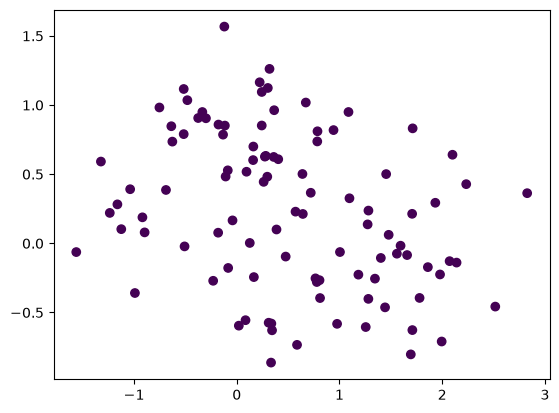

In [22]:
import matplotlib.pyplot as plt
import numpy as np

y = np.zeros(len(X))  # Recreates y to match the new size of X (17 items)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

In [23]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

model = Sequential()

model.add(Dense(128, input_dim=2, activation="relu"))
model.add(Dense(128, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

adam = Adam(learning_rate=0.01)
model.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history = model.fit(X, y, epochs=500, validation_split=0.2, verbose=1)

Epoch 1/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step - accuracy: 0.8875 - loss: 0.4573 - val_accuracy: 1.0000 - val_loss: 0.1059
Epoch 2/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 1.0000 - loss: 0.0575 - val_accuracy: 1.0000 - val_loss: 0.0074
Epoch 3/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 1.0000 - loss: 0.0038 - val_accuracy: 1.0000 - val_loss: 3.6634e-04
Epoch 4/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 1.0000 - loss: 2.0722e-04 - val_accuracy: 1.0000 - val_loss: 2.0021e-05
Epoch 5/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 1.0000 - loss: 9.1758e-06 - val_accuracy: 1.0000 - val_loss: 1.4862e-06
Epoch 6/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 1.0000 - loss: 8.3280e-07 - val_accuracy: 1.0000 - val_loss: 1.6290e-07
Epoch 7/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 1.0000 - loss: 6.6048e-08 - val_accuracy: 1.0000 - val_loss: 2.6200e-08
Epoch 8/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 1.96

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step


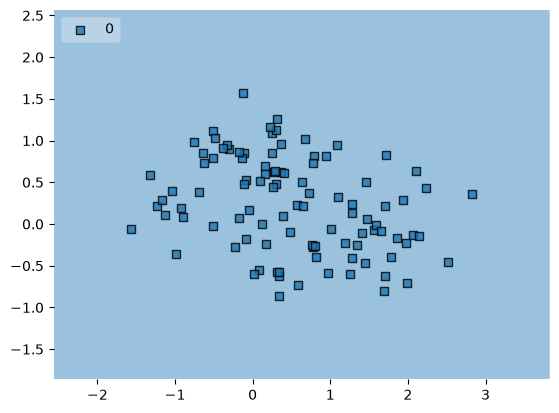

In [24]:
import numpy as np
from mlxtend.plotting import plot_decision_regions

# Create a small wrapper class so mlxtend works smoothly with Keras probability outputs
class KerasClassifierWrapper:
    def __init__(self, model):
        self.model = model
    def predict(self, X):
        return (self.model.predict(X) > 0.5).astype(int).flatten()

# Wrap your trained model
clf_wrapped = KerasClassifierWrapper(model)

# Plot decision regions using the wrapper
plot_decision_regions(X, y.astype('int'), clf=clf_wrapped, legend=2)
plt.show()

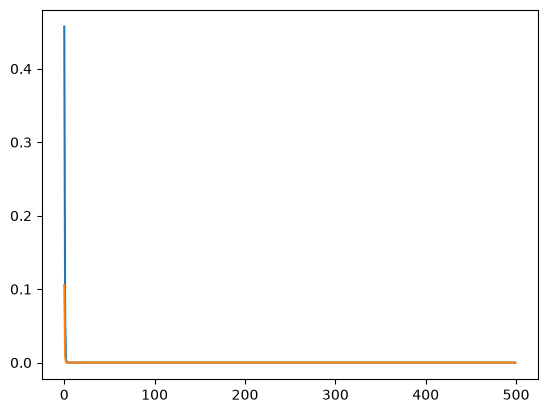

In [25]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

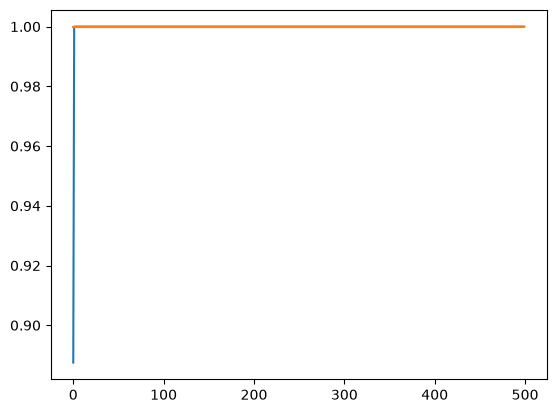

In [26]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

In [32]:
from tensorflow.keras.layers import Dense, Dropout

model = Sequential()

model.add(Dense(128, input_dim=2, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(1, activation="sigmoid"))

adam = Adam(learning_rate=0.01)
model.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

history = model.fit(X, y, epochs=100, validation_split=0.2, verbose=1)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 173ms/step - accuracy: 0.7000 - loss: 0.5364 - val_accuracy: 1.0000 - val_loss: 0.1606
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 1.0000 - loss: 0.0966 - val_accuracy: 1.0000 - val_loss: 0.0174
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 1.0000 - loss: 0.0100 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 1.0000 - loss: 0.0022 - val_accuracy: 1.0000 - val_loss: 8.5586e-05
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 1.0000 - loss: 4.1194e-05 - val_accuracy: 1.0000 - val_loss: 7.0771e-06
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 1.0000 - loss: 9.1733e-06 - val_accuracy: 1.0000 - val_loss: 8.0073e-07
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 1.0000 - loss: 1.0854e-05 - val_accuracy: 1.0000 - val_loss: 1.2921e-07
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 1.0000 - loss: 8.4727e-07 -

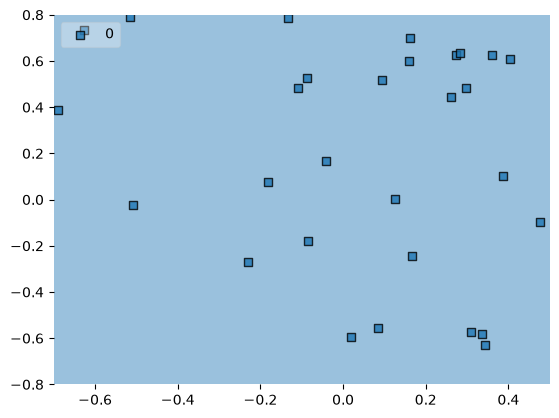

In [33]:
import numpy as np
from mlxtend.plotting import plot_decision_regions

# Custom wrapper class to format Keras outputs for mlxtend
class KerasClassifierWrapper:
    def __init__(self, model):
        self.model = model
    def predict(self, X):
        return (self.model.predict(X, verbose=0) > 0.5).astype(int).flatten()

# Wrap your trained model
clf_wrapped = KerasClassifierWrapper(model)

# Plot decision regions using the wrapped model
plot_decision_regions(X, y.astype('int'), clf=clf_wrapped, legend=2)
plt.xlim(-0.7, 0.5)
plt.ylim(-0.8, 0.8)
plt.show()

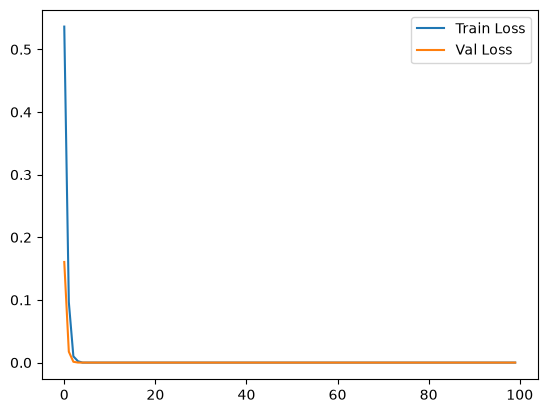

In [34]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.show()